In [8]:
import pandas as pd

df = pd.read_csv("swiggy_cleaned.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset size:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

First 5 rows:
                         hotel_name rating time_minutes  \
0                        McDonald's    4.5           27   
1                               KFC    4.2           30   
2                    Domino's Pizza    4.3           25   
3  Charcoal Eats - Biryani & Beyond    4.3           24   
4                        Sandwizzaa    4.6           22   

                                       food_type        location offer_above  \
0             Burgers, Beverages, Cafe, Desserts  Kandivali East          75   
1  Burgers, Biryani, American, Snacks, Fast Food  Kandivali East          80   
2              Pizzas, Italian, Pastas, Desserts  Thakur Village         299   
3      Biryani, Kebabs, Hyderabadi, North Indian  Malad Kan East         100   
4             Snacks, Fast Food, Beverages, Jain  Kandivali East         120   

  offer_percentage  
0               30  
1               40  
2    not_available  
3               50  
4               60  

Dataset size:
(1730, 7)

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Dataset load karo
df = pd.read_csv("swiggy_cleaned.csv")

# Graphs save karne ke liye folder
Path("reports/eda").mkdir(parents=True, exist_ok=True)

# 1. Dataset ka size
print("\n--- DATASET SIZE ---")
print("Rows and columns:", df.shape)

# 2. Column names aur data types
print("\n--- DATA TYPES ---")
print(df.dtypes)

# 3. Missing values
print("\n--- MISSING VALUES ---")
missing = df.isnull().sum()
print(missing[missing > 0])

# 4. Duplicate records
print("\n--- DUPLICATE ROWS ---")
print("Duplicates:", df.duplicated().sum())

# 5. Statistical summary
print("\n--- DATA SUMMARY ---")
print(df.describe(include="all").T)

# 6. Numerical columns ke graphs
numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols[:5]:
    df[col].dropna().hist(bins=20)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig(f"reports/eda/{col}_distribution.png")
    plt.close()

# 7. Categorical columns ke top values
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

for col in categorical_cols[:3]:
    counts = df[col].value_counts().head(10)

    if not counts.empty:
        counts.plot(kind="bar")
        plt.title(f"Top 10 Values: {col}")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.tight_layout()
        plt.savefig(f"reports/eda/{col}_top_values.png")
        plt.close()

print("\nInitial EDA complete.")
print("Check the reports/eda folder for graphs.")


--- DATASET SIZE ---
Rows and columns: (1730, 7)

--- DATA TYPES ---
hotel_name          object
rating              object
time_minutes        object
food_type           object
location            object
offer_above         object
offer_percentage    object
dtype: object

--- MISSING VALUES ---
time_minutes    343
dtype: int64

--- DUPLICATE ROWS ---
Duplicates: 0

--- DATA SUMMARY ---
                 count unique            top  freq
hotel_name        1730   1729      Theobroma     2
rating            1730     73            4.4   191
time_minutes      1387     79             44    58
food_type         1730   1009        Chinese    79
location          1730    122       Borivali   309
offer_above       1730     52  not_available   976
offer_percentage  1730     10  not_available  1330

Initial EDA complete.
Check the reports/eda folder for graphs.


In [10]:
import pandas as pd
from pathlib import Path

# Dataset paths
input_path = Path("swiggy_cleaned.csv")
output_path = Path("swiggy_cleaned.csv")

# Check dataset exists
if not input_path.exists():
    raise FileNotFoundError(
        f"Dataset nahi mili: {input_path.resolve()}"
    )

# Load original dataset
df = pd.read_csv(input_path)

print("Original dataset shape:", df.shape)

# 1. Blank strings ko missing values mein convert karo
text_columns = df.select_dtypes(
    include=["object", "string"]
).columns

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace("", pd.NA)

# 2. Exact duplicate rows count karo
duplicate_count = df.duplicated().sum()
print("Exact duplicate rows:", duplicate_count)

# 3. Exact duplicate rows remove karo
df = df.drop_duplicates().copy()

# 4. Missing values report karo
print("\nMissing values by column:")
print(df.isnull().sum())

print("\nMissing-value percentage:")
print((df.isnull().mean() * 100).round(2))

# 5. Save cleaned copy
output_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(output_path, index=False)

print("\nCleaned dataset shape:", df.shape)
print("Cleaned file saved at:", output_path)

Original dataset shape: (1730, 7)
Exact duplicate rows: 0

Missing values by column:
hotel_name            0
rating                0
time_minutes        343
food_type             0
location              0
offer_above           0
offer_percentage      0
dtype: int64

Missing-value percentage:
hotel_name           0.00
rating               0.00
time_minutes        19.83
food_type            0.00
location             0.00
offer_above          0.00
offer_percentage     0.00
dtype: float64

Cleaned dataset shape: (1730, 7)
Cleaned file saved at: swiggy_cleaned.csv


In [11]:
import pandas as pd

df = pd.read_csv("swiggy_cleaned.csv")

print("\n--- FIRST 10 ROWS ---")
print(df.head(10).to_string(index=False))

print("\n--- DATA TYPES ---")
print(df.dtypes)

print("\n--- COMPLETE DATA SUMMARY ---")
print(df.describe(include="all").T)

print("\n--- DELIVERY TIME SUMMARY ---")
print(df["time_minutes"].describe())

print("\n--- RATING VALUES ---")
print(df["rating"].value_counts(dropna=False).head(15))

print("\n--- FOOD TYPE VALUES ---")
print(df["food_type"].value_counts(dropna=False).head(15))

print("\n--- LOCATION VALUES ---")
print(df["location"].value_counts(dropna=False).head(15))


--- FIRST 10 ROWS ---
                      hotel_name rating time_minutes                                        food_type       location   offer_above offer_percentage
                      McDonald's    4.5           27               Burgers, Beverages, Cafe, Desserts Kandivali East            75               30
                             KFC    4.2           30    Burgers, Biryani, American, Snacks, Fast Food Kandivali East            80               40
                  Domino's Pizza    4.3           25                Pizzas, Italian, Pastas, Desserts Thakur Village           299    not_available
Charcoal Eats - Biryani & Beyond    4.3           24        Biryani, Kebabs, Hyderabadi, North Indian Malad Kan East           100               50
                      Sandwizzaa    4.6           22               Snacks, Fast Food, Beverages, Jain Kandivali East           120               60
                   1441 Pizzeria    3.8           32                          Italian, Pi

In [12]:
import pandas as pd

# Cleaned dataset load karo
df = pd.read_csv("swiggy_cleaned.csv")

# Columns jo numerical hone chahiye
numeric_columns = [
    "rating",
    "time_minutes",
    "offer_above",
    "offer_percentage"
]

# Unavailable values ko missing values mein convert karo
for col in numeric_columns:
    df[col] = df[col].astype("string").str.strip().str.lower()

    df[col] = df[col].replace(
        ["not_available", "not available", "n/a", "na", ""],
        pd.NA
    )

    df[col] = pd.to_numeric(df[col], errors="coerce")

# Results check karo
print("UPDATED DATA TYPES")
print(df.dtypes)

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nNUMERICAL SUMMARY")
print(df[numeric_columns].describe())

# Original file ko safe rakhkar nayi file save karo
df.to_csv("swiggy_typed.csv", index=False)

print("\nSaved successfully: swiggy_typed.csv")

UPDATED DATA TYPES
hotel_name           object
rating              Float64
time_minutes          Int64
food_type            object
location             object
offer_above           Int64
offer_percentage      Int64
dtype: object

MISSING VALUES
hotel_name             0
rating               343
time_minutes         358
food_type              0
location               0
offer_above          981
offer_percentage    1330
dtype: int64

NUMERICAL SUMMARY
         rating  time_minutes  offer_above  offer_percentage
count    1387.0        1372.0        749.0             400.0
mean   4.128983     42.594752    462.64753           27.8875
std    0.489054     11.421909   370.423621         16.015339
min         1.5          12.0         40.0              10.0
25%         4.0          35.0        120.0              15.0
50%         4.2          43.0        449.0              22.5
75%         4.4          50.0        749.0              40.0
max         5.0          81.0       1999.0              60.0

UNAVAILABLE VALUES IN ORIGINAL DATA
rating: 0
time_minutes: 0
offer_above: 976
offer_percentage: 1330

MISSING VALUE PERCENTAGE
hotel_name           0.00
food_type            0.00
location             0.00
rating              19.83
time_minutes        20.69
offer_above         56.71
offer_percentage    76.88
dtype: float64


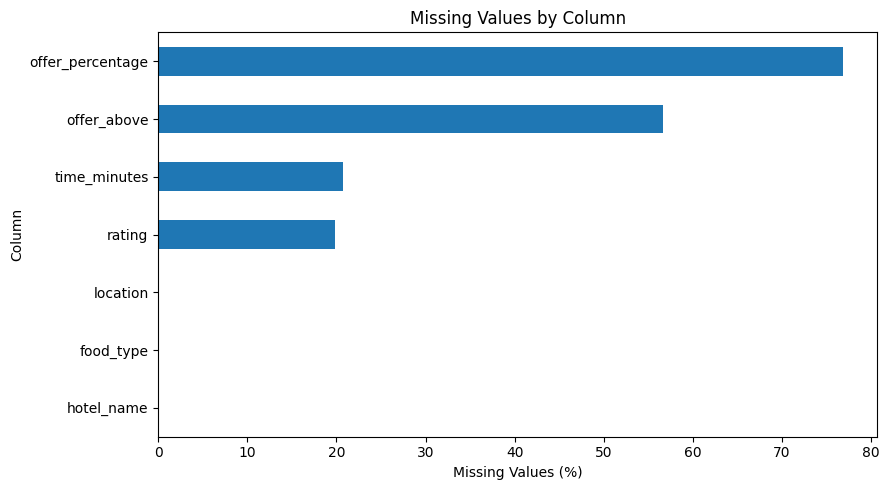

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Original cleaned dataset aur converted dataset load karo
raw_df = pd.read_csv("swiggy_cleaned.csv")
typed_df = pd.read_csv("swiggy_typed.csv")

numeric_columns = [
    "rating",
    "time_minutes",
    "offer_above",
    "offer_percentage"
]

# Original dataset mein unavailable values check karo
print("UNAVAILABLE VALUES IN ORIGINAL DATA")

for col in numeric_columns:
    values = raw_df[col].astype("string").str.strip().str.lower()

    count = values.isin([
        "not_available",
        "not available",
        "n/a",
        "na",
        ""
    ]).sum()

    print(f"{col}: {count}")

# Missing values ka percentage
missing_percent = (
    typed_df.isnull().mean() * 100
).sort_values()

print("\nMISSING VALUE PERCENTAGE")
print(missing_percent.round(2))

# Missing values ka graph
plt.figure(figsize=(9, 5))
missing_percent.plot(kind="barh")

plt.title("Missing Values by Column")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

In [14]:
import pandas as pd

# Original cleaned dataset load karo
raw_df = pd.read_csv("swiggy_cleaned.csv")

# Values ko normalize karo
for col in ["offer_above", "offer_percentage"]:
    raw_df[col] = raw_df[col].astype("string").str.strip().str.lower()

# Original data mein unavailable values check karo
print("OFFER ABOVE VALUES")
print(raw_df["offer_above"].value_counts(dropna=False).head(10))

print("\nOFFER PERCENTAGE VALUES")
print(raw_df["offer_percentage"].value_counts(dropna=False).head(10))

# Dono offer columns ka missing pattern check karo
offer_above_missing = raw_df["offer_above"].isin(
    ["not_available", "not available", "n/a", "na", ""]
) | raw_df["offer_above"].isna()

offer_percentage_missing = raw_df["offer_percentage"].isin(
    ["not_available", "not available", "n/a", "na", ""]
) | raw_df["offer_percentage"].isna()

print("\nOFFER DATA COMBINATIONS")
print(pd.crosstab(
    offer_above_missing,
    offer_percentage_missing,
    rownames=["Offer Above Missing"],
    colnames=["Offer Percentage Missing"]
))

# Example rows inspect karo
print("\nEXAMPLE RESTAURANTS WITH UNAVAILABLE OFFERS")
print(
    raw_df.loc[
        offer_above_missing | offer_percentage_missing,
        ["hotel_name", "offer_above", "offer_percentage"]
    ].head(15).to_string(index=False)
)

OFFER ABOVE VALUES
offer_above
not_available    976
449               94
999               86
100               78
150               36
120               33
50                33
749               29
499               29
700               28
Name: count, dtype: Int64

OFFER PERCENTAGE VALUES
offer_percentage
not_available    1330
10                 92
20                 76
50                 61
30                 55
40                 32
15                 32
60                 27
25                 24
35                  1
Name: count, dtype: Int64

OFFER DATA COMBINATIONS
Offer Percentage Missing  False  True 
Offer Above Missing                   
False                       400    354
True                          0    976

EXAMPLE RESTAURANTS WITH UNAVAILABLE OFFERS
                          hotel_name   offer_above offer_percentage
                      Domino's Pizza           299    not_available
                   Love & Cheesecake not_available    not_available
               

In [15]:
import pandas as pd

raw_df = pd.read_csv("swiggy_cleaned.csv")

# Unavailable values identify karo
def is_unavailable(series):
    values = series.astype("string").str.strip().str.lower()
    return values.isna() | values.isin([
        "not_available",
        "not available",
        "n/a",
        "na",
        ""
    ])

above_missing = is_unavailable(raw_df["offer_above"])
percentage_missing = is_unavailable(raw_df["offer_percentage"])

# Dono columns ka missing-value relationship
print("MISSING VALUE COMBINATIONS")

print(pd.crosstab(
    above_missing,
    percentage_missing,
    rownames=["offer_above missing"],
    colnames=["offer_percentage missing"],
    margins=True
))

# Har situation ke kuch examples
groups = {
    "Both missing": above_missing & percentage_missing,
    "Both available": ~above_missing & ~percentage_missing,
    "Only offer_above missing": above_missing & ~percentage_missing,
    "Only offer_percentage missing": ~above_missing & percentage_missing
}

for title, mask in groups.items():
    print(f"\n--- {title} ---")
    print(
        raw_df.loc[
            mask,
            ["hotel_name", "offer_above", "offer_percentage"]
        ].head(5).to_string(index=False)
    )

MISSING VALUE COMBINATIONS
offer_percentage missing  False  True   All
offer_above missing                        
False                       400   354   754
True                          0   976   976
All                         400  1330  1730

--- Both missing ---
                          hotel_name   offer_above offer_percentage
                   Love & Cheesecake not_available    not_available
                           Atta Girl not_available    not_available
         Poetry By Love & Cheesecake not_available    not_available
            Havmor Havfunn Ice Cream not_available    not_available
McDonald's Gourmet Burger Collection not_available    not_available

--- Both available ---
                      hotel_name offer_above offer_percentage
                      McDonald's          75               30
                             KFC          80               40
Charcoal Eats - Biryani & Beyond         100               50
                      Sandwizzaa         120       

In [16]:
import pandas as pd

# Cleaned dataset load karo
raw_df = pd.read_csv("swiggy_cleaned.csv")

# Missing ya unavailable values identify karo
def is_unavailable(series):
    values = series.astype("string").str.strip().str.lower()

    return values.isna() | values.isin([
        "not_available",
        "not available",
        "n/a",
        "na",
        ""
    ])

above_missing = is_unavailable(raw_df["offer_above"])
percentage_missing = is_unavailable(raw_df["offer_percentage"])

# Dono columns ki missing values compare karo
print("MISSING VALUE COMBINATIONS")

print(pd.crosstab(
    above_missing,
    percentage_missing,
    rownames=["offer_above missing"],
    colnames=["offer_percentage missing"],
    margins=True
))

# Har situation ke 5 examples dekho
groups = {
    "Both missing": above_missing & percentage_missing,
    "Both available": ~above_missing & ~percentage_missing,
    "Only offer_above missing": above_missing & ~percentage_missing,
    "Only offer_percentage missing": ~above_missing & percentage_missing
}

for title, mask in groups.items():
    print(f"\n--- {title} ---")

    print(
        raw_df.loc[
            mask,
            ["hotel_name", "offer_above", "offer_percentage"]
        ].head(5).to_string(index=False)
    )

MISSING VALUE COMBINATIONS
offer_percentage missing  False  True   All
offer_above missing                        
False                       400   354   754
True                          0   976   976
All                         400  1330  1730

--- Both missing ---
                          hotel_name   offer_above offer_percentage
                   Love & Cheesecake not_available    not_available
                           Atta Girl not_available    not_available
         Poetry By Love & Cheesecake not_available    not_available
            Havmor Havfunn Ice Cream not_available    not_available
McDonald's Gourmet Burger Collection not_available    not_available

--- Both available ---
                      hotel_name offer_above offer_percentage
                      McDonald's          75               30
                             KFC          80               40
Charcoal Eats - Biryani & Beyond         100               50
                      Sandwizzaa         120       

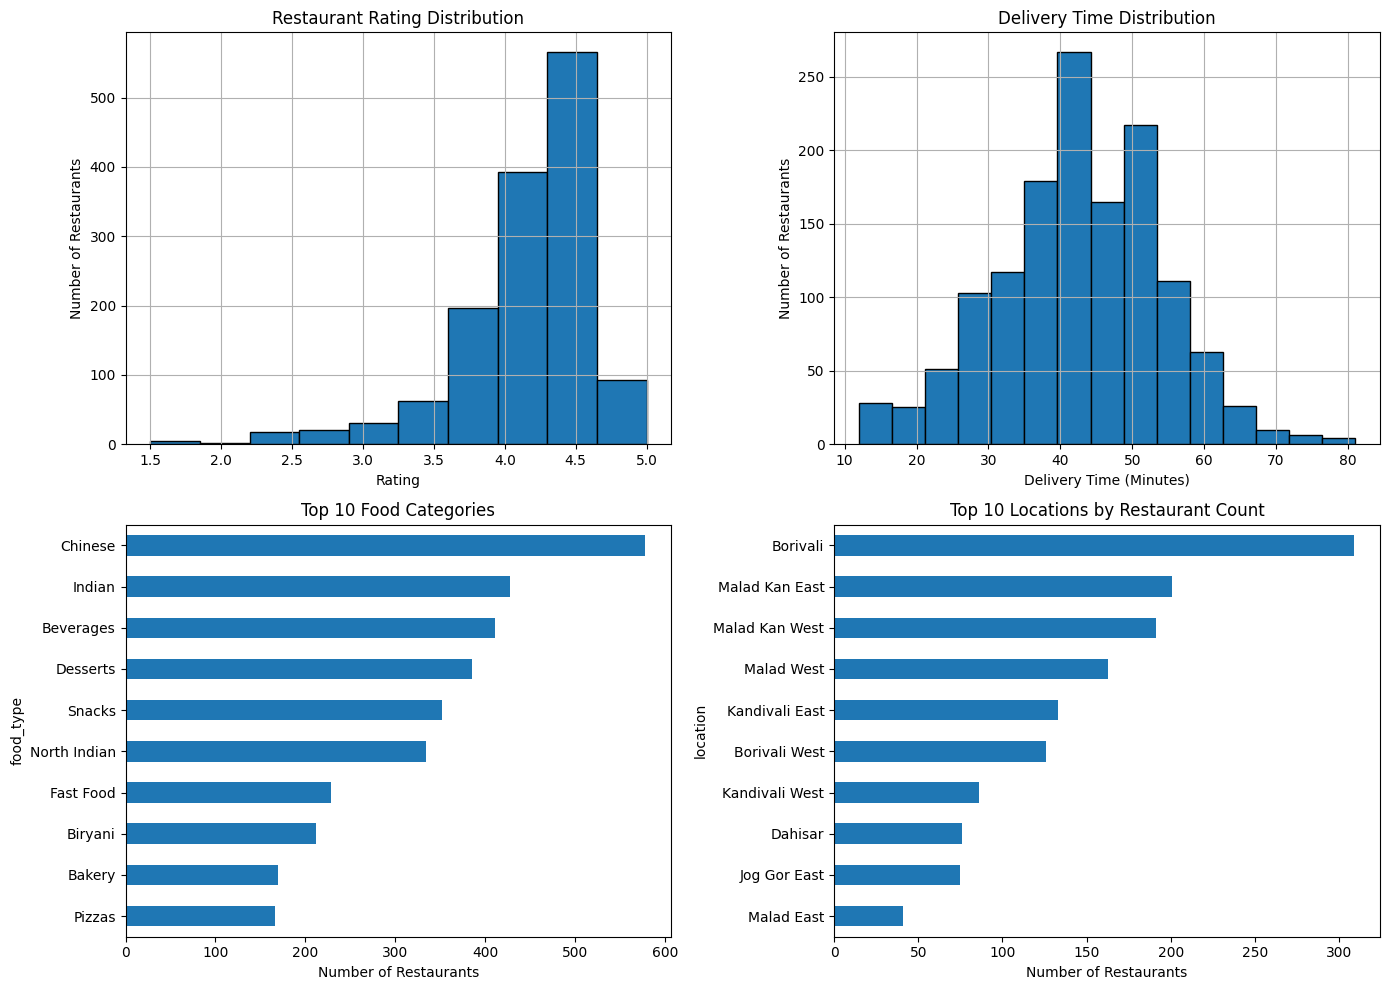

Average rating: 4.13
Median rating: 4.2
Average delivery time: 42.59 minutes
Median delivery time: 43.0 minutes

Top 10 food categories:
food_type
Chinese         578
Indian          428
Beverages       411
Desserts        385
Snacks          352
North Indian    334
Fast Food       228
Biryani         212
Bakery          169
Pizzas          166
Name: count, dtype: int64


In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# Converted dataset load karo
df = pd.read_csv("swiggy_typed.csv")

# Numerical columns ko ensure karo
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
df["time_minutes"] = pd.to_numeric(
    df["time_minutes"], errors="coerce"
)

# 4 EDA graphs
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Rating distribution
df["rating"].dropna().hist(
    bins=10, ax=axes[0, 0], edgecolor="black"
)
axes[0, 0].set_title("Restaurant Rating Distribution")
axes[0, 0].set_xlabel("Rating")
axes[0, 0].set_ylabel("Number of Restaurants")

# 2. Delivery time distribution
df["time_minutes"].dropna().hist(
    bins=15, ax=axes[0, 1], edgecolor="black"
)
axes[0, 1].set_title("Delivery Time Distribution")
axes[0, 1].set_xlabel("Delivery Time (Minutes)")
axes[0, 1].set_ylabel("Number of Restaurants")

# 3. Most common food categories
food_counts = (
    df["food_type"]
    .dropna()
    .astype(str)
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
    .sort_values()
)

food_counts.plot(kind="barh", ax=axes[1, 0])
axes[1, 0].set_title("Top 10 Food Categories")
axes[1, 0].set_xlabel("Number of Restaurants")

# 4. Locations with the most restaurants
location_counts = (
    df["location"]
    .dropna()
    .astype(str)
    .str.strip()
    .value_counts()
    .head(10)
    .sort_values()
)

location_counts.plot(kind="barh", ax=axes[1, 1])
axes[1, 1].set_title("Top 10 Locations by Restaurant Count")
axes[1, 1].set_xlabel("Number of Restaurants")

plt.tight_layout()
plt.show()

# Important numerical insights
print("Average rating:", round(df["rating"].mean(), 2))
print("Median rating:", round(df["rating"].median(), 2))
print(
    "Average delivery time:",
    round(df["time_minutes"].mean(), 2), "minutes"
)
print(
    "Median delivery time:",
    round(df["time_minutes"].median(), 2), "minutes"
)

print("\nTop 10 food categories:")
print(food_counts.sort_values(ascending=False))

In [18]:
import pandas as pd

df = pd.read_csv("swiggy_typed.csv")

# Numerical columns ki summary
columns = [
    "rating",
    "time_minutes",
    "offer_above",
    "offer_percentage"
]

print("NUMERICAL SUMMARY")
print(df[columns].describe().round(2))

# Ratings: expected range 1 to 5
invalid_rating = df[
    df["rating"].notna()
    & ~df["rating"].between(1, 5)
]

# Delivery time: zero ya negative values check karo
invalid_time = df[
    df["time_minutes"].notna()
    & (df["time_minutes"] <= 0)
]

# Offer percentage: expected range 0 to 100
invalid_percentage = df[
    df["offer_percentage"].notna()
    & ~df["offer_percentage"].between(0, 100)
]

# Offer threshold: negative values check karo
invalid_threshold = df[
    df["offer_above"].notna()
    & (df["offer_above"] < 0)
]

print("\nINVALID VALUE COUNTS")
print("Ratings outside 1-5:", len(invalid_rating))
print("Zero/negative delivery times:", len(invalid_time))
print("Offer percentages outside 0-100:", len(invalid_percentage))
print("Negative offer thresholds:", len(invalid_threshold))

NUMERICAL SUMMARY
        rating  time_minutes  offer_above  offer_percentage
count  1387.00       1372.00       749.00            400.00
mean      4.13         42.59       462.65             27.89
std       0.49         11.42       370.42             16.02
min       1.50         12.00        40.00             10.00
25%       4.00         35.00       120.00             15.00
50%       4.20         43.00       449.00             22.50
75%       4.40         50.00       749.00             40.00
max       5.00         81.00      1999.00             60.00

INVALID VALUE COUNTS
Ratings outside 1-5: 0
Zero/negative delivery times: 0
Offer percentages outside 0-100: 0
Negative offer thresholds: 0


In [1]:
import pandas as pd

# Typed dataset load karo
df = pd.read_csv("swiggy_typed.csv")

# Check original missing values
print("MISSING VALUES BEFORE PROCESSING")
print(df.isnull().sum())

# Missing-value indicators create karo
df["rating_was_missing"] = df["rating"].isnull().astype(int)
df["time_was_missing"] = df["time_minutes"].isnull().astype(int)

# Rating aur delivery time mein median se missing values fill karo
# Original typed file ko change nahi karenge
df["rating"] = df["rating"].fillna(df["rating"].median())
df["time_minutes"] = df["time_minutes"].fillna(
    df["time_minutes"].median()
)

# Offer columns ka status banao; missing ko zero nahi manenge
has_threshold = df["offer_above"].notna()
has_percentage = df["offer_percentage"].notna()

df["offer_info_status"] = "Not listed"

df.loc[
    has_threshold & has_percentage,
    "offer_info_status"
] = "Complete details"

df.loc[
    has_threshold & ~has_percentage,
    "offer_info_status"
] = "Partial details"

# Results check karo
print("\nMISSING VALUES AFTER PROCESSING")
print(df.isnull().sum())

print("\nOFFER INFORMATION STATUS")
print(df["offer_info_status"].value_counts())

# New file save karo
df.to_csv("swiggy_preprocessed.csv", index=False)

print("\nSaved: swiggy_preprocessed.csv")

MISSING VALUES BEFORE PROCESSING
hotel_name             0
rating               343
time_minutes         358
food_type              0
location               0
offer_above          981
offer_percentage    1330
dtype: int64

MISSING VALUES AFTER PROCESSING
hotel_name               0
rating                   0
time_minutes             0
food_type                0
location                 0
offer_above            981
offer_percentage      1330
rating_was_missing       0
time_was_missing         0
offer_info_status        0
dtype: int64

OFFER INFORMATION STATUS
offer_info_status
Not listed          981
Complete details    399
Partial details     350
Name: count, dtype: int64

Saved: swiggy_preprocessed.csv


In [2]:
import pandas as pd

df = pd.read_csv("swiggy_preprocessed.csv")

print("OFFER STATUS COUNTS")
print(df["offer_info_status"].value_counts(dropna=False))

print("\nOFFER MISSING VALUE CROSS-TAB")
print(pd.crosstab(
    df["offer_above"].isna(),
    df["offer_percentage"].isna(),
    margins=True
))

print("\nFINAL DATASET SHAPE")
print(df.shape)

OFFER STATUS COUNTS
offer_info_status
Not listed          981
Complete details    399
Partial details     350
Name: count, dtype: int64

OFFER MISSING VALUE CROSS-TAB
offer_percentage  False  True   All
offer_above                        
False               399   350   749
True                  1   980   981
All                 400  1330  1730

FINAL DATASET SHAPE
(1730, 10)


In [3]:
import pandas as pd

# Original aur converted datasets
raw_df = pd.read_csv("swiggy_cleaned.csv", dtype="string")
typed_df = pd.read_csv("swiggy_typed.csv")

# Unavailable values ki list
missing_labels = [
    "not_available",
    "not available",
    "n/a",
    "na",
    ""
]

for col in ["offer_above", "offer_percentage"]:

    original = raw_df[col].str.strip().str.lower()

    known_missing = (
        original.isna() |
        original.isin(missing_labels)
    )

    converted_missing = typed_df[col].isna()

    # Values jo conversion ke baad missing hui,
    # lekin original mein known missing nahi thi
    unexpected = converted_missing & ~known_missing

    print(f"\n--- UNEXPECTED VALUES: {col} ---")
    print("Count:", unexpected.sum())

    print(
        raw_df.loc[
            unexpected,
            ["hotel_name", col]
        ].to_string(index=False)
    )

# One-sided missing records inspect karo
one_sided = (
    typed_df["offer_above"].isna() ^
    typed_df["offer_percentage"].isna()
)

print("\n--- ONE-SIDED MISSING OFFER RECORDS ---")

print(
    pd.concat(
        [raw_df.loc[one_sided],
         typed_df.loc[one_sided, ["offer_above", "offer_percentage"]]],
        axis=1
    ).to_string(index=False)
)


--- UNEXPECTED VALUES: offer_above ---
Count: 5
        hotel_name offer_above
Nishi Home Delites   FREE ITEM
        Shawarmaji   FREE ITEM
Saffron Restaurant   FREE ITEM
 Natural Ice Cream     20% OFF
       Ladu Samrat   FREE ITEM

--- UNEXPECTED VALUES: offer_percentage ---
Count: 0
Empty DataFrame
Columns: [hotel_name, offer_percentage]
Index: []

--- ONE-SIDED MISSING OFFER RECORDS ---
                                        hotel_name  rating time_minutes                                                                                                                      food_type                     location  offer_above  offer_percentage  offer_above  offer_percentage
                                    Domino's Pizza     4.3           25                                                                                              Pizzas, Italian, Pastas, Desserts               Thakur Village          299     not_available        299.0               NaN
                        

In [4]:
import pandas as pd

raw_df = pd.read_csv("swiggy_cleaned.csv", dtype="string")

# offer_above ko numeric mein convert karke
# identify karo ki kaunse records convert nahi hue
values = raw_df["offer_above"].str.strip()

numeric_values = pd.to_numeric(
    values, errors="coerce"
)

mask = (
    values.notna()
    & numeric_values.isna()
    & ~values.str.lower().isin([
        "not_available",
        "not available",
        "n/a",
        "na",
        ""
    ])
)

# Complete records print karo
print("SPECIAL OFFER RECORDS")

print(
    raw_df.loc[mask, :].to_string(index=False)
)

print("\nTOTAL RECORDS:", mask.sum())

SPECIAL OFFER RECORDS
        hotel_name rating time_minutes                                                   food_type                      location offer_above offer_percentage
Nishi Home Delites    4.6           27                                             Indian, Punjabi                Kandivali East   FREE ITEM    not_available
        Shawarmaji    4.4           16                                                    Lebanese Thakur village Kandivali east   FREE ITEM    not_available
Saffron Restaurant    4.1           31           North Indian, Chinese, Beverages, Tandoor, Kebabs                Kandivali East   FREE ITEM    not_available
 Natural Ice Cream    4.7           21                                         Ice Cream, Desserts                  Avenue Hotel     20% OFF               20
       Ladu Samrat    4.3           43 Maharashtrian, Snacks, Street Food, Indian, Desserts, Chaat                Kandivali East   FREE ITEM    not_available

TOTAL RECORDS: 5


In [5]:
import pandas as pd

raw_df = pd.read_csv("swiggy_cleaned.csv", dtype="string")

values = raw_df["offer_above"].str.strip()

# Special offers identify karo
mask = values.str.contains(
    r"FREE ITEM|% OFF",
    case=False,
    na=False
)

# Sirf required columns display karo
special_offers = raw_df.loc[
    mask,
    ["hotel_name", "offer_above", "offer_percentage"]
]

print(special_offers.to_string(index=False))

print("\nTotal special offers:", len(special_offers))

        hotel_name offer_above offer_percentage
Nishi Home Delites   FREE ITEM    not_available
        Shawarmaji   FREE ITEM    not_available
Saffron Restaurant   FREE ITEM    not_available
 Natural Ice Cream     20% OFF               20
       Ladu Samrat   FREE ITEM    not_available

Total special offers: 5


In [6]:
import pandas as pd

# Original cleaned dataset load karo
df = pd.read_csv("swiggy_cleaned.csv")

# Original offer values preserve karo
raw_offer = df["offer_above"].astype("string").str.strip()
raw_pct = df["offer_percentage"].astype("string").str.strip()

# Missing labels
missing_labels = [
    "not_available", "not available", "n/a", "na", ""
]

# Offer threshold ko numeric banao
threshold_text = raw_offer.mask(
    raw_offer.str.lower().isin(missing_labels)
)

df["offer_threshold"] = pd.to_numeric(
    threshold_text, errors="coerce"
)

# Discount percentage numeric banao
percentage_text = raw_pct.mask(
    raw_pct.str.lower().isin(missing_labels)
)

df["offer_percentage_clean"] = pd.to_numeric(
    percentage_text, errors="coerce"
)

# Offer type identify karo
df["offer_type"] = "Not Listed"

free_item = raw_offer.str.contains(
    "FREE ITEM", case=False, na=False
)

percentage_offer = (
    raw_offer.str.contains("% OFF", case=False, na=False)
    | df["offer_percentage_clean"].notna()
)

threshold_only = (
    df["offer_threshold"].notna()
    & df["offer_percentage_clean"].isna()
)

df.loc[threshold_only, "offer_type"] = "Partial Details"
df.loc[percentage_offer, "offer_type"] = "Percentage Discount"
df.loc[free_item, "offer_type"] = "Free Item"

# Results
print("OFFER TYPE DISTRIBUTION")
print(df["offer_type"].value_counts())

print("\nSPECIAL OFFERS")
print(
    df.loc[
        free_item | raw_offer.str.contains(
            "% OFF", case=False, na=False
        ),
        ["hotel_name", "offer_above",
         "offer_percentage", "offer_type"]
    ].to_string(index=False)
)

# Save new dataset
df.to_csv("swiggy_offer_features.csv", index=False)

print("\nSaved: swiggy_offer_features.csv")

OFFER TYPE DISTRIBUTION
offer_type
Not Listed             976
Percentage Discount    400
Partial Details        350
Free Item                4
Name: count, dtype: int64

SPECIAL OFFERS
        hotel_name offer_above offer_percentage          offer_type
Nishi Home Delites   FREE ITEM    not_available           Free Item
        Shawarmaji   FREE ITEM    not_available           Free Item
Saffron Restaurant   FREE ITEM    not_available           Free Item
 Natural Ice Cream     20% OFF               20 Percentage Discount
       Ladu Samrat   FREE ITEM    not_available           Free Item

Saved: swiggy_offer_features.csv


Available records: 1372
Rating vs Delivery Time Correlation: -0.064


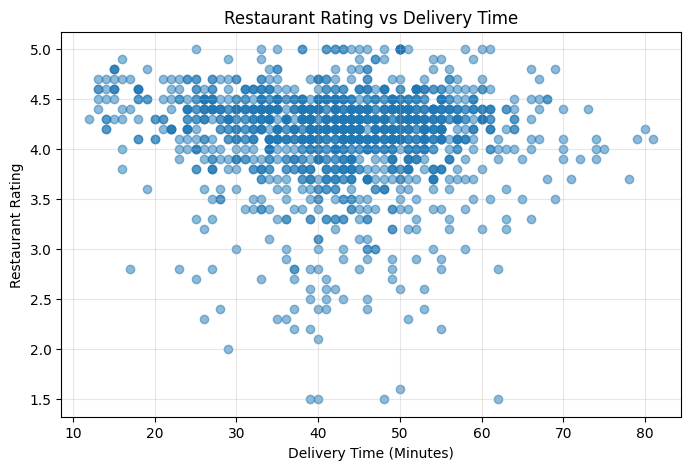

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Typed dataset load karo
df = pd.read_csv("swiggy_typed.csv")

# Sirf available rating aur delivery time records
data = df[["rating", "time_minutes"]].dropna()

# Correlation calculate karo
correlation = data["rating"].corr(
    data["time_minutes"]
)

print("Available records:", len(data))
print("Rating vs Delivery Time Correlation:", round(correlation, 3))

# Scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(
    data["time_minutes"],
    data["rating"],
    alpha=0.5
)

plt.title("Restaurant Rating vs Delivery Time")
plt.xlabel("Delivery Time (Minutes)")
plt.ylabel("Restaurant Rating")
plt.grid(alpha=0.3)

plt.show()

TOP 10 FOOD CATEGORIES BY AVERAGE RATING
                  average_rating  restaurant_count
food_type                                         
Gujarati                    4.41                15
Italian-American            4.35                11
Jain                        4.35                12
Tibetan                     4.32                14
Ice Cream                   4.30                83
Sweets                      4.30                76
Mexican                     4.23                34
Maharashtrian               4.21                28
Punjabi                     4.21                36
American                    4.20                43


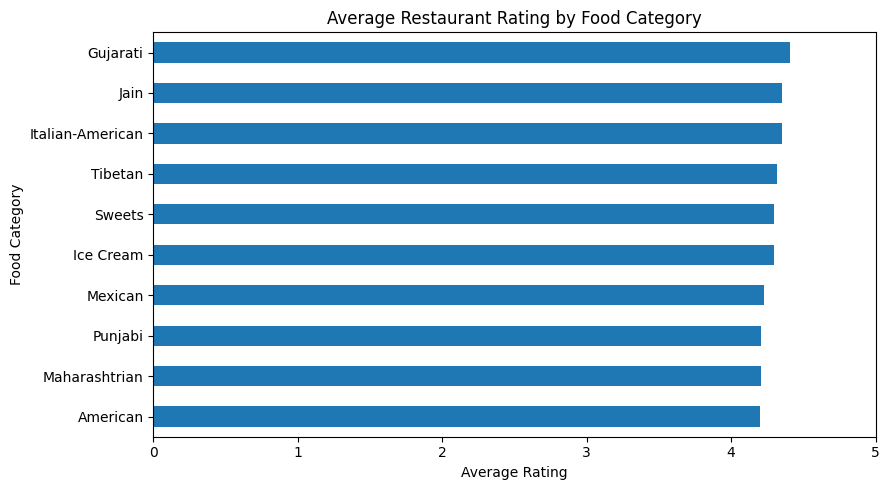

                  average_rating  restaurant_count
food_type                                         
Gujarati                    4.41                15
Italian-American            4.35                11
Jain                        4.35                12
Tibetan                     4.32                14
Ice Cream                   4.30                83
Sweets                      4.30                76
Mexican                     4.23                34
Maharashtrian               4.21                28
Punjabi                     4.21                36
American                    4.20                43


In [9]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("swiggy_typed.csv")

# Food categories ko separate karo
category_df = df[["food_type", "rating"]].dropna().copy()

category_df["food_type"] = (
    category_df["food_type"].str.split(",")
)

category_df = category_df.explode("food_type")

category_df["food_type"] = (
    category_df["food_type"].str.strip()
)

# Category-wise rating calculate karo
category_rating = (
    category_df.groupby("food_type")
    .agg(
        average_rating=("rating", "mean"),
        restaurant_count=("rating", "count")
    )
    .round(2)
)

# Minimum 10 restaurants wali categories
category_rating = category_rating[
    category_rating["restaurant_count"] >= 10
]

# Top 10 categories by average rating
top_categories = category_rating.sort_values(
    "average_rating", ascending=False
).head(10)

print("TOP 10 FOOD CATEGORIES BY AVERAGE RATING")
print(top_categories)

# Graph
top_categories.sort_values("average_rating").plot(
    kind="barh",
    y="average_rating",
    legend=False,
    figsize=(9, 5)
)

plt.title("Average Restaurant Rating by Food Category")
plt.xlabel("Average Rating")
plt.ylabel("Food Category")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()
print(top_categories.to_string())

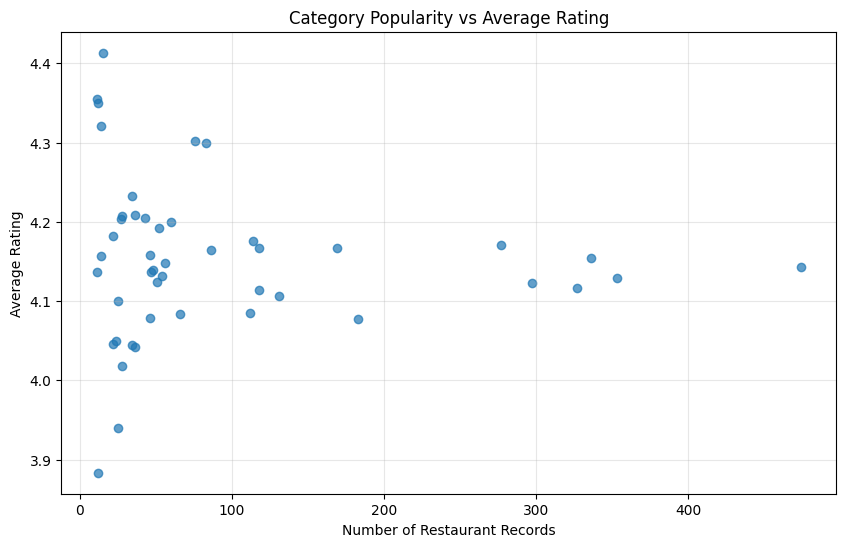


TOP 10 POPULAR CATEGORIES
   food_type  average_rating  restaurant_count
     Chinese        4.142405               474
      Indian        4.129462               353
    Desserts        4.154167               336
   Beverages        4.115902               327
North Indian        4.122559               297
      Snacks        4.171119               277
     Biryani        4.077049               183
   Fast Food        4.166864               169
      Pizzas        4.106107               131
South Indian        4.166949               118


In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("swiggy_typed.csv")

# Category data prepare karo
data = df[["food_type", "rating"]].dropna().copy()

data["food_type"] = data["food_type"].str.split(",")
data = data.explode("food_type")

data["food_type"] = data["food_type"].str.strip()

# Category-wise rating and count
category_analysis = data.groupby("food_type").agg(
    average_rating=("rating", "mean"),
    restaurant_count=("rating", "count")
).reset_index()

# Minimum 10 records
category_analysis = category_analysis[
    category_analysis["restaurant_count"] >= 10
]

# Scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    category_analysis["restaurant_count"],
    category_analysis["average_rating"],
    alpha=0.7
)

plt.title("Category Popularity vs Average Rating")
plt.xlabel("Number of Restaurant Records")
plt.ylabel("Average Rating")
plt.grid(alpha=0.3)

plt.show()

# Top 10 most represented categories
print("\nTOP 10 POPULAR CATEGORIES")
print(
    category_analysis.sort_values(
        "restaurant_count",
        ascending=False
    ).head(10).to_string(index=False)
)

In [11]:
# Category count vs average rating correlation

pearson_corr = category_analysis[
    "restaurant_count"
].corr(category_analysis["average_rating"])

spearman_corr = category_analysis[
    "restaurant_count"
].corr(
    category_analysis["average_rating"],
    method="spearman"
)

print("Total categories:", len(category_analysis))

print("Pearson Correlation:", round(pearson_corr, 3))

print("Spearman Correlation:", round(spearman_corr, 3))

ModuleNotFoundError: No module named 'scipy'

In [12]:
# Pearson Correlation
pearson_corr = category_analysis[
    "restaurant_count"
].corr(category_analysis["average_rating"])

# Spearman Correlation without SciPy
rank_count = category_analysis[
    "restaurant_count"
].rank(method="average")

rank_rating = category_analysis[
    "average_rating"
].rank(method="average")

spearman_corr = rank_count.corr(rank_rating)

print("Total Categories:", len(category_analysis))

print("Pearson Correlation:", round(pearson_corr, 3))

print("Spearman Correlation:", round(spearman_corr, 3))

Total Categories: 46
Pearson Correlation: -0.075
Spearman Correlation: -0.103


TOP 10 LOCATIONS BY AVERAGE RATING
      location  average_rating  restaurant_count
 Goregaon West            4.26                11
 Borivali West            4.24               124
 Borivali East            4.22                17
Kandivali East            4.20               129
Kandivali West            4.19                82
    Malad West            4.19               158
Malad Kan West            4.18               119
  Dahisar East            4.17                22
 Goregaon East            4.15                29
Malad Kan East            4.13               132


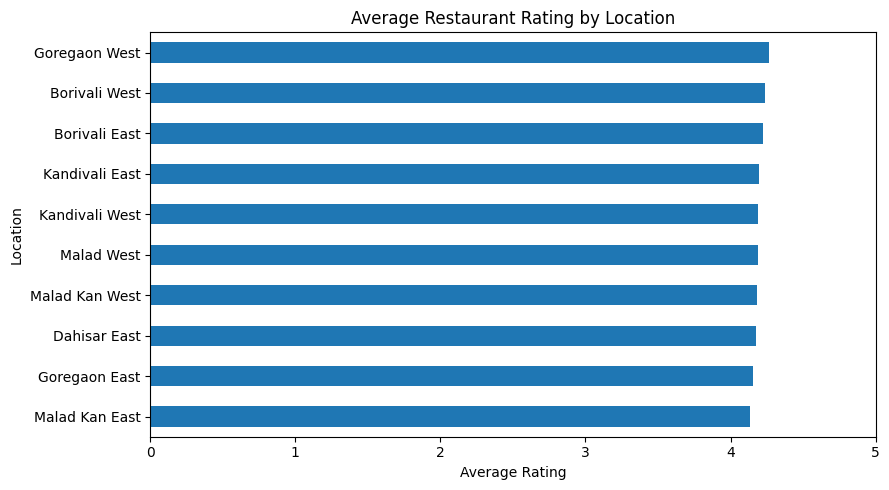

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("swiggy_typed.csv")

# Location-wise rating analysis
location_analysis = df.groupby("location").agg(
    average_rating=("rating", "mean"),
    restaurant_count=("rating", "count")
).reset_index()

# Minimum 10 rated restaurants
location_analysis = location_analysis[
    location_analysis["restaurant_count"] >= 10
]

# Top 10 locations by average rating
top_locations = location_analysis.sort_values(
    "average_rating", ascending=False
).head(10)

print("TOP 10 LOCATIONS BY AVERAGE RATING")

print(top_locations.round(2).to_string(index=False))

# Visualization
top_locations.sort_values("average_rating").plot(
    kind="barh",
    x="location",
    y="average_rating",
    legend=False,
    figsize=(9, 5)
)

plt.title("Average Restaurant Rating by Location")
plt.xlabel("Average Rating")
plt.ylabel("Location")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

TOP 10 LOCATIONS BY FASTEST DELIVERY TIME
      location  average_delivery_time  restaurant_count
Kandivali East                  29.04               118
 Borivali East                  34.06                17
Malad Kan East                  34.19               132
      Borivali                  39.68               219
  Dahisar East                  40.32                22
Kandivali West                  41.00                82
 Borivali West                  41.33               124
       Dahisar                  42.38                48
    Malad East                  42.76                38
  Jog Gor East                  49.69                51


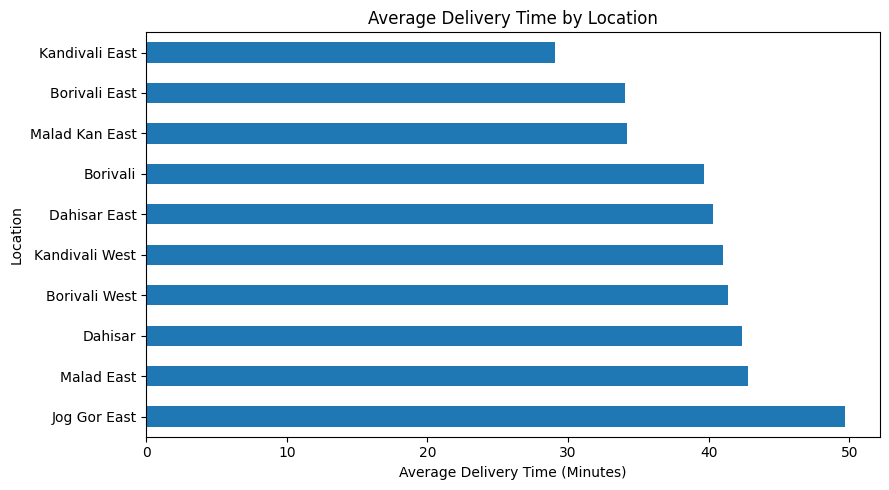

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("swiggy_typed.csv")

# Location-wise delivery analysis
location_delivery = df.groupby("location").agg(
    average_delivery_time=("time_minutes", "mean"),
    restaurant_count=("time_minutes", "count")
).reset_index()

# At least 10 restaurants with available delivery time
location_delivery = location_delivery[
    location_delivery["restaurant_count"] >= 10
]

# 10 fastest locations
fastest_locations = location_delivery.sort_values(
    "average_delivery_time"
).head(10)

print("TOP 10 LOCATIONS BY FASTEST DELIVERY TIME")

print(
    fastest_locations.round(2).to_string(index=False)
)

# Graph
fastest_locations.sort_values(
    "average_delivery_time",
    ascending=False
).plot(
    kind="barh",
    x="location",
    y="average_delivery_time",
    legend=False,
    figsize=(9, 5)
)

plt.title("Average Delivery Time by Location")
plt.xlabel("Average Delivery Time (Minutes)")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

In [15]:
import pandas as pd

df = pd.read_csv("swiggy_typed.csv")

print("TOTAL UNIQUE LOCATIONS:")
print(df["location"].nunique())

print("\nALL LOCATION NAMES WITH COUNTS:")

print(
    df["location"]
    .value_counts(dropna=False)
    .to_string()
)

TOTAL UNIQUE LOCATIONS:
122

ALL LOCATION NAMES WITH COUNTS:
location
Borivali                                         309
Malad Kan East                                   201
Malad Kan West                                   191
Malad West                                       163
Kandivali East                                   133
Borivali West                                    126
Kandivali West                                    86
Dahisar                                           76
Jog Gor East                                      75
Malad East                                        41
Goregaon                                          39
Goregaon East                                     31
Dahisar East                                      23
Dahisar West                                      20
Borivali East                                     17
Mira Road                                         14
Jog Gor West                                      12
Goregaon West                

In [16]:
import pandas as pd

df = pd.read_csv("swiggy_typed.csv")

# Original location names
locations = df["location"].astype("string")

# Remove extra spaces
clean_locations = locations.str.strip()

# Case-insensitive comparison
location_key = clean_locations.str.casefold()

# Original names aur normalized keys
location_check = pd.DataFrame({
    "original_location": locations,
    "normalized_key": location_key
})

# Different spellings/cases with same normalized key
variants = (
    location_check
    .dropna()
    .groupby("normalized_key")
    .agg(
        original_names=(
            "original_location",
            lambda x: sorted(x.unique().tolist())
        ),
        total_records=("original_location", "count")
    )
)

# Sirf multiple name variants show karo
variants = variants[
    variants["original_names"].apply(len) > 1
]

print("LOCATION NAME INCONSISTENCIES")

print(variants.to_string())

print("\nTotal inconsistent location groups:", len(variants))

LOCATION NAME INCONSISTENCIES
                                                  original_names  total_records
normalized_key                                                                 
borivali                                    [BORIVALI, Borivali]            311
borivali east      [BORIVALI EAST, Borivali East, Borivali east]             19
borivali west      [BORIVALI WEST, Borivali West, Borivali west]            130
dahisar west                        [Dahisar West, Dahisar west]             21
kandivali                                 [Kandivali, kandivali]              8
kandivali east  [Kandivali East, Kandivali east, kandivali east]            135
kandivali west  [KANDIVALI WEST, Kandivali West, Kandivali west]             90
malad                                             [MALAD, Malad]              8
malad kan east                  [Malad Kan East, Malad kan east]            203
malad west      [MALAD WEST, Malad West, Malad west, malad west]            166

Total inc